# Image Transformations Lab

All of the programming assignments are to be done in Python using additional libraries specified in the assignments. There are many libraries available, some of which we will be using, and you are welcome to use them with one exception: if the library or a function within it performs the specific function you are asked to code, you may not use that other than perhaps as a reference to compare against. All of the code you submit must be your own. You are welcome to turn in a completed jupyter notebook.

**Note:** In most math classes, the direction of the positve Y-axis is up. In this lab (and most image packages), the direction of the positive Y-axis is down. This means that you will need to rotate in the opposite direction of what you might intuitively think.

**Note:** For this lab you will need a package called Python Image Libary or PIL. You may need to install it into your python environment with `conda install pillow` or `pip install pillow`.


#### Preliminary Code


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Set the default figure size for all plots
plt.rcParams['figure.figsize'] = [10, 8]

def compose(frame, image, transformation):
    
    width, height = frame.size
    
    #Invert matrix for compose function, grab values for Affine Transform
    t = np.linalg.inv(transformation)
    a=t[0,0]; b=t[0,1]; c=t[0,2]; d=t[1,0]; e=t[1,1]; f=t[1,2]
    
    image = image.transform((width,height), Image.AFFINE,(a,b,c,d,e,f), Image.BICUBIC)

    #Make mask from image's location
    im = np.sum(np.asarray(image), -1)
    vals = 255.0*( im > 0)
    mask = Image.fromarray(vals).convert("1")

    #Composite images together
    result = Image.composite(image,frame,mask)

    return result

#### Your Defined Transformations

For this lab you will take a set of 12 images that are given to you, then perform the appropriate translations, rotations, and scales to place those images in the locations specified in the output collage. You will need to provide the appropriate transformation matrices to place the other 11. The transformation matrices should assume homogenous coordinates. One of the 12 images has been done for you in the code below.

Tip: Make sure you are comfortable with building your own transformations and how the compositing code works, then try implementing your own function that generates transformation matrices based on scale, roation, and translation values.


Bird0.png:
[[  1.   0. 619.]
 [  0.   1. 433.]
 [  0.   0.   1.]]

Bird1.png:
[[ 1.21  0.   41.  ]
 [ 0.    1.21 30.  ]
 [ 0.    0.    1.  ]]

Bird2.png:
[[  0.389   0.    283.   ]
 [  0.      0.389  46.   ]
 [  0.      0.      1.   ]]

Bird3.png:
[[  0.866025   0.5      419.      ]
 [ -0.5        0.866025  87.      ]
 [  0.         0.         1.      ]]

Bird4.png:
[[  0.63075   -0.169009 673.      ]
 [  0.169009   0.63075   37.      ]
 [  0.         0.         1.      ]]

Bird5.png:
[[  0.707107  -0.707107 350.      ]
 [  0.707107   0.707107 138.      ]
 [  0.         0.         1.      ]]

Bird6.png:
[[  0.389   0.    514.   ]
 [  0.      0.389 225.   ]
 [  0.      0.      1.   ]]

Bird7.png:
[[  0.710921   0.190491 633.      ]
 [ -0.190491   0.710921 228.      ]
 [  0.         0.         1.      ]]

Bird8.png:
[[  1.16877    0.313171  46.      ]
 [ -0.313171   1.16877  354.      ]
 [  0.         0.         1.      ]]

Bird9.png:
[[  0.275065  -0.275065 305.      ]
 [  0.275065   0.

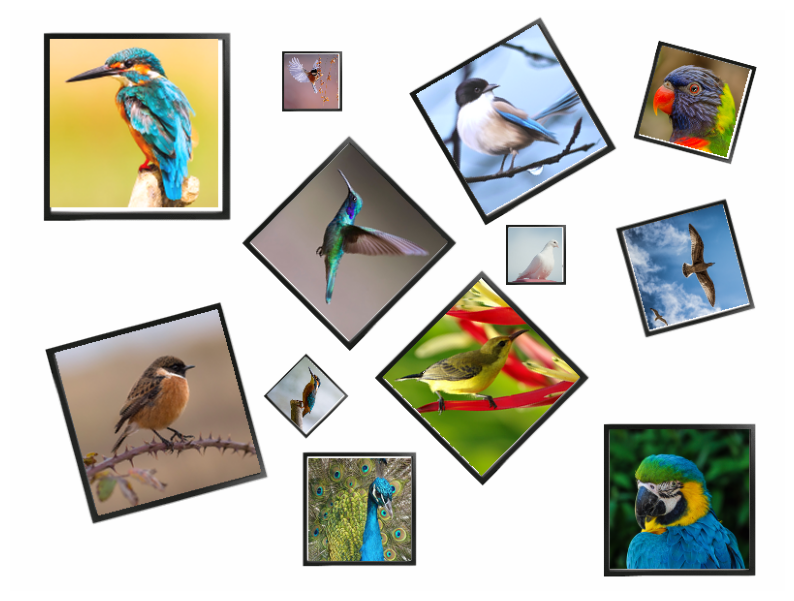

In [ ]:
#Open the two images
# filename = "PictureFrameCollage.png"
# frame = Image.open(filename).convert("RGB")

# filename0 = "Bird0.png"
# im = Image.open(filename0).convert("RGB")

# #Define the transformation to the first picture frame
# transformation = np.matrix([[1,0,619],[0,1,433],[0,0,1]])

# #Compose the two images together
# result = compose(frame, im, transformation)
    
# #Show the result
# plt.imshow(result)
# plt.show()

#Uncomment this line if you want to save the image
#result.save("Output.png")



# Function for creating a homogeneous transformation

def make_transformation(scale=1.0, angle=0.0, tx=0.0, ty=0.0):

    # Convert degrees to radians because numpy.sin/cos use radians.
    theta = np.deg2rad(angle)

    # Scaling matrix.
    S = np.array([
        [scale, 0,     0],
        [0,     scale, 0],
        [0,     0,     1]
    ], dtype=float)

    # Rotation matrix.
    R = np.array([
        [np.cos(theta),  np.sin(theta), 0],
        [-np.sin(theta), np.cos(theta), 0],
        [0,              0,             1]
    ], dtype=float)

    # Translation matrix.
    T = np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ], dtype=float)

    # Apply scale, then rotation, then translation.
    return T @ R @ S

transform_specs = {
    "Bird0.png":  {"scale": 1.000, "angle":   0, "tx": 619, "ty": 433},
    "Bird1.png":  {"scale": 1.210, "angle":   0, "tx":  41, "ty":  30},
    "Bird2.png":  {"scale": 0.389, "angle":   0, "tx": 283, "ty":  46},
    "Bird3.png":  {"scale": 1.000, "angle":  30, "tx": 419, "ty":  87},
    "Bird4.png":  {"scale": 0.653, "angle": -15, "tx": 673, "ty":  37},
    "Bird5.png":  {"scale": 1.000, "angle": -45, "tx": 350, "ty": 138},
    "Bird6.png":  {"scale": 0.389, "angle":   0, "tx": 514, "ty": 225},
    "Bird7.png":  {"scale": 0.736, "angle":  15, "tx": 633, "ty": 228},
    "Bird8.png":  {"scale": 1.210, "angle":  15, "tx":  46, "ty": 354},
    "Bird9.png":  {"scale": 0.389, "angle": -45, "tx": 305, "ty": 358},
    "Bird10.png": {"scale": 1.000, "angle":  45, "tx": 385, "ty": 379},
    "Bird11.png": {"scale": 0.736, "angle":   0, "tx": 308, "ty": 463},
}


# Create all 12 matrices.
transformations = {}

for filename, values in transform_specs.items():
    transformations[filename] = make_transformation(**values)

np.set_printoptions(precision=6, suppress=True)

for filename, matrix in transformations.items():
    print(f"{filename}:")
    print(matrix)
    print()


result = frame.copy()

# Add each bird using its transformation matrix.
for filename, transformation in transformations.items():

    # Open the bird image.
    image = Image.open(filename).convert("RGB")

    # Put the transformed image onto the collage.
    result = compose(result, image, transformation)


# Display the completed collage.
plt.figure(figsize=(10, 8))
plt.imshow(result)
plt.axis("off")
plt.show()


result.save("Output.png")
